# 10 · How the target was generated (generator study, phase 3)

**Phase 1** (`09`) showed the model is data-limited: AUC still climbs with more rows (ceiling ≈ 0.735). A model with the generator's true structure would learn more from the same data.

**Method:** an explainable boosting machine (EBM: one learned curve per feature, plus chosen pairs) is used as a probe. Its pair search pointed at `QUOTE_YEAR` in almost every strong interaction, which led to the main finding below.

**Contents**
1. Evidence: the conversion logic changes on **2017-01-01**.
2. EBM variants on the 15 fixed folds: additive, additive *per era*, plus the one within-era pair found.
3. The recovered per-era shapes (the generator "spec").
4. Blend of CatBoost (current best, 0.7143) with the per-era EBM; weights set on seed-0 folds, judged on seeds 1–2.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
sys.path.insert(0, '.')
import common as C, features as FE

lab, hold = C.load()
L = FE.add_era(FE.add_cats(FE.add_static(lab)))
F = json.load(open('params_tuned.json'))['cb']['features']          # the 41 features
PC = json.load(open('params_cats.json'))
cb = C.cv_score('cats15___copies__ohm_10', L, PC['features'], 'cb', PC['params'], notes='07_catboost_cats')   # cached: current best
y = L[C.TARGET].to_numpy()
FOLDS = C.folds(lab)
fmt = {'auc': '{:.4f}', 'Δ auc': '{:+.4f}', 'se Δ': '{:.4f}', 'Δ seeds 1-2': '{:+.4f}', 'se seeds 1-2': '{:.4f}', 'top_decile': '{:.1%}'}
def sauc(g, c):
    m = g[c].notna()
    return roc_auc_score(g[C.TARGET][m], g[c][m].astype(float)) - 0.5
print(f'CatBoost (07) 15-fold AUC {cb["auc_mean"]:.4f}')

CatBoost (07) 15-fold AUC 0.7143


## 1. The conversion logic changes on 2017-01-01
Signed univariate AUC (AUC − 0.5; positive = higher value converts more) of key features, by quarter.

,DRV_HIGH_EDU_SHARE,QUOTED_AMT,CREDIT_SCORE,ACS_POP_DENSITY,DISCOUNT_IND,quotes,conv. rate
_Q,,,,,,,
2015Q1,0.004012,-0.057771,0.057430,0.038875,0.015867,2090,11.5%
2015Q2,0.015860,-0.089608,0.081346,0.006396,0.018700,2108,12.0%
2015Q3,0.056986,-0.114686,0.118020,0.042433,0.003316,2199,12.1%
2015Q4,0.046060,-0.097030,0.100418,0.073063,0.021012,2299,12.0%
2016Q1,0.021545,-0.098241,0.083884,0.023648,0.065737,2405,10.8%
2016Q2,0.023625,-0.095989,0.078527,0.046868,0.075326,2461,11.7%
2016Q3,0.038701,-0.104534,0.081986,0.051198,0.065488,2412,12.0%
2016Q4,0.004552,-0.105890,0.075596,0.026463,0.079563,2497,10.5%
2017Q1,0.114011,-0.010040,0.014794,0.059842,0.021534,1003,10.7%


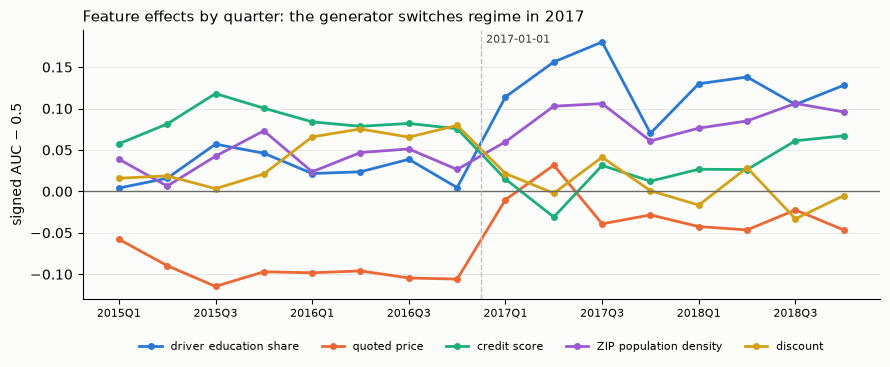

In [2]:
L['_Q'] = pd.to_datetime(L.QUOTE_DT).dt.to_period('Q').astype(str)
KEY = {'DRV_HIGH_EDU_SHARE': 'driver education share', 'QUOTED_AMT': 'quoted price', 'CREDIT_SCORE': 'credit score',
       'ACS_POP_DENSITY': 'ZIP population density', 'DISCOUNT_IND': 'discount'}
q = L.groupby('_Q').apply(lambda g: pd.Series({c: sauc(g, c) for c in KEY} | {'quotes': len(g), 'conv. rate': g[C.TARGET].mean()}))
display(q.style.format('{:+.3f}', subset=list(KEY)).format({'quotes': '{:.0f}', 'conv. rate': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(9, 3.8))
cols = ['#2a78d6', '#eb6834', '#1baf7a', '#9b59d0', '#d4a017']
x = np.arange(len(q))
for (c, lbl), col in zip(KEY.items(), cols):
    ax.plot(x, q[c], color=col, lw=2, marker='o', ms=4, label=lbl)
ax.axhline(0, color='#6b6a66', lw=1)
ax.axvline(7.5, color='#c3c2bd', lw=1, ls='--'); ax.text(7.6, ax.get_ylim()[1] * 0.92, '2017-01-01', fontsize=8, color='#3d3c39')
ax.set_xticks(x[::2]); ax.set_xticklabels(q.index[::2], fontsize=8)
ax.set_ylabel('signed AUC − 0.5'); ax.legend(frameon=False, fontsize=8, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12))
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
ax.set_title('Feature effects by quarter: the generator switches regime in 2017', loc='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb'); fig.tight_layout()
fig.savefig('figures/10_regime_change.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()

**Reading:** a clean break at **2017-01-01**. Through 2016Q4, price (−0.10) and credit (+0.08) dominate; from 2017Q1 both collapse toward 0 while driver education jumps from ~+0.02 to ~+0.13 and density roughly doubles. Discount matters only during 2016 (+0.07). Quote volume also drops ~60% in 2017. The overall conversion rate barely changes, so the generator re-weighted the drivers rather than shifting the base rate.

## 2. EBM probes (15 folds, paired vs. CatBoost)
- **additive:** one curve per feature, no pairs (seed-0 folds only; a reference).
- **per-era additive:** plus an `ERA × feature` pair for every feature, so each era (2015 / 2016 / 2017-18) gets its own curve.
- **per-era + price × age:** plus the one within-era pair the pair search found (quoted price × mean driver age).

In [3]:
FE_EBM = F + ['ERA']
def vs_cb(r):
    k = len(r['fold_aucs'])
    d = r['fold_aucs'] - cb['fold_aucs'][:k]
    out = {'auc': r['auc_mean'], 'Δ auc': d.mean(), 'se Δ': d.std() / np.sqrt(k), 'top_decile': r['top_decile_prec'], 'folds': k}
    if k == 15:
        out |= {'Δ seeds 1-2': d[5:].mean(), 'se seeds 1-2': d[5:].std() / np.sqrt(10)}
    return out
E = {
    'additive (seed 0)':     C.cv_score('ebm_add', L, F, 'ebm', {'interactions': 0}, seeds=(0,), notes='10 EBM additive'),
    'per-era additive':      C.cv_score('ebm_era3', L, FE_EBM, 'ebm', {'interactions': 'era'}, notes='10 EBM per era'),
    'per-era + price × age': C.cv_score('ebm_era3_pxa', L, FE_EBM, 'ebm', {'interactions': 'era', 'pairs_extra': [('QUOTED_AMT', 'DRV_AGE_MEAN')]},
                                        notes='10 EBM per era + price x age'),
}
pd.DataFrame({k: vs_cb(r) for k, r in E.items()}).T.style.format(fmt, na_rep='')

,auc,Δ auc,se Δ,top_decile,folds,Δ seeds 1-2,se seeds 1-2
additive (seed 0),0.6938,-0.0204,0.0020,26.9%,5.000000,,
per-era additive,0.7120,-0.0023,0.0006,30.0%,15.000000,-0.0022,0.0009
per-era + price × age,0.7117,-0.0026,0.0006,30.1%,15.000000,-0.0024,0.0008


**Reading:**
- **Era structure explains most of the gap between an additive model and CatBoost:** additive EBM 0.6938 → per-era additive **0.7120** (+0.018), only **−0.0023 ± 0.0006** behind CatBoost (0.7143).
- So the generator is close to **a separate additive logit per era**. CatBoost's remaining edge is small: a few within-era interactions, or sharper thresholds.
- The price × age pair adds nothing (0.7117): not a real generator term.

## 3. The recovered shapes, per era
EBM per-era model fitted on all labeled quotes. Each curve is the feature's contribution to the log-odds of converting within one era (partial dependence; exact for an additive-per-era model), centered at its mean.

/Users/joerussell/Desktop/PROJECTS/competitions/travelers-umc/.venv/lib/python3.12/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


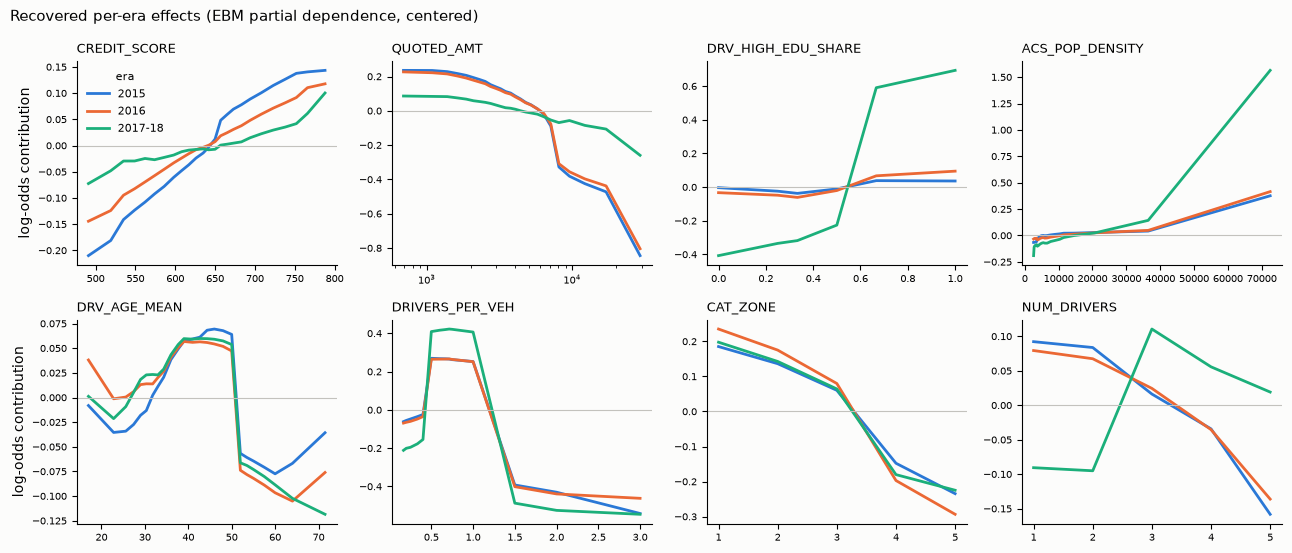

,importance (mean |log-odds|)
DRIVERS_PER_VEH,0.2088
DRV_AGE_35_50,0.1995
ERA & DRV_HIGH_EDU_SHARE,0.1783
PRIOR_CARRIER_GRP,0.1515
CAT_ZONE,0.1448
DRV_HIGH_EDU_SHARE,0.1305
QUOTED_AMT,0.1218
COV_PKG_TYPE,0.0882
ERA & DRIVERS_PER_VEH,0.0658
DISCOUNT_IND,0.0634


In [4]:
best_ebm = max(['per-era additive', 'per-era + price × age'], key=lambda k: E[k]['auc_mean'])
ebm_params = {'interactions': 'era'} | ({'pairs_extra': [('QUOTED_AMT', 'DRV_AGE_MEAN')]} if 'price' in best_ebm else {})
m = C.ebm_model(L[FE_EBM], ebm_params).fit(C.ebm_X(L[FE_EBM]), y)
SHAPES = ['CREDIT_SCORE', 'QUOTED_AMT', 'DRV_HIGH_EDU_SHARE', 'ACS_POP_DENSITY', 'DRV_AGE_MEAN', 'DRIVERS_PER_VEH', 'CAT_ZONE', 'NUM_DRIVERS']
ERAS = ['2015', '2016', '2017-18']
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for ax, f in zip(axes.ravel(), SHAPES):
    grid = np.unique(np.nanquantile(L[f].astype(float), np.linspace(0.02, 0.98, 25)))
    for era, col in zip(ERAS, ['#2a78d6', '#eb6834', '#1baf7a']):
        base = L[L.ERA == era].sample(300, random_state=0)
        lo = []
        for g in grid:
            X = C.ebm_X(base[FE_EBM].assign(**{f: g}))
            p = m.predict_proba(X)[:, 1]
            lo.append(np.mean(np.log(p / (1 - p))))
        lo = np.array(lo)
        ax.plot(grid, lo - lo.mean(), color=col, lw=2, label=era)
    ax.set_title(f, fontsize=9, loc='left'); ax.axhline(0, color='#c3c2bd', lw=0.8)
    ax.tick_params(labelsize=7)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if f == 'QUOTED_AMT': ax.set_xscale('log')
axes[0, 0].set_ylabel('log-odds contribution'); axes[1, 0].set_ylabel('log-odds contribution')
axes[0, 0].legend(frameon=False, fontsize=8, title='era', title_fontsize=8)
fig.suptitle('Recovered per-era effects (EBM partial dependence, centered)', x=0.01, ha='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb')
for ax in axes.ravel(): ax.set_facecolor('#fcfcfb')
fig.tight_layout(); fig.savefig('figures/10_era_shapes.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()
imp = pd.Series(m.term_importances(), index=m.term_names_).sort_values(ascending=False)
imp.head(20).round(4).to_frame('importance (mean |log-odds|)')

**Reading: the recovered generator spec.** The curves show hard-coded-looking cutoffs:
| Feature | 2015 / 2016 | 2017-18 |
|---|---|---|
| quoted price | flat to ~$5k, **step down at ~$7.5k** (−0.3), then falls further | weak, gradual decline |
| credit score | rising ~linearly (+0.35 over 500–800), small jump at 650 in 2015 | weaker (+0.17) |
| driver education share | no effect | **step up at 0.5** (−0.4 → +0.6, the largest single effect) |
| ZIP density | mild rise | strong rise above ~35k/sq mi |
| mean driver age | **band 35–50**, sharp drop at 50 | same |
| drivers per vehicle | **high in [0.5, 1.0]**, sharp drop above 1 (more drivers than cars) | same, stronger |
| CAT zone | linear decline by zone | same |
| number of drivers | declines with drivers | peaks at 3 |
| discount | 2016 only | none |

The thresholds (price ~$7.5k, education share 0.5, age 35/50, drivers per vehicle 0.5/1.0) look like literal constants in the generator code.

## 4. Blend CatBoost + per-era EBM
Weight on the EBM searched over 0–1 (step 0.05) on the **seed-0** repeat, for probability and rank averaging; judged on **seeds 1–2** against CatBoost alone. Adopt only with Δ > 2·se there.

In [5]:
from scipy.stats import spearmanr
eb = E[best_ebm]
print(f'rank correlation CatBoost vs EBM (OOF): {spearmanr(cb["oof_all"][0], eb["oof_all"][0])[0]:.3f}')
def fold_rank(P):
    R = np.zeros_like(P)
    for s, k, tr, va in FOLDS:
        R[s, va] = pd.Series(P[s, va]).rank(pct=True).to_numpy()
    return R
def aucs(P):
    return np.array([roc_auc_score(y[va], P[s, va]) for s, k, tr, va in FOLDS])
src = {'prob': (cb['oof_all'], eb['oof_all']), 'rank': (fold_rank(cb['oof_all']), fold_rank(eb['oof_all']))}
W = np.round(np.arange(0, 1.0001, 0.05), 2)
rows, best = [], {}
for how, (a, b) in src.items():
    s0 = [aucs((1 - w) * a + w * b)[:5].mean() for w in W]
    w = W[int(np.argmax(s0))]; best[how] = w
    d = aucs((1 - w) * a + w * b) - cb['fold_aucs']
    rows.append({'blend': how, 'EBM weight (seed 0)': w, 'auc': aucs((1 - w) * a + w * b).mean(), 'Δ auc': d.mean(), 'se Δ': d.std() / np.sqrt(15),
                 'Δ seeds 1-2': d[5:].mean(), 'se seeds 1-2': d[5:].std() / np.sqrt(10)})
bl = pd.DataFrame(rows).set_index('blend')
display(bl.style.format(fmt | {'EBM weight (seed 0)': '{:.2f}'}))
pick = 'prob' if bl.loc['prob', 'Δ seeds 1-2'] >= bl.loc['rank', 'Δ seeds 1-2'] - bl.loc['rank', 'se seeds 1-2'] else 'rank'  # prob keeps calibrated, untied scores
adopt = bl.loc[pick, 'Δ seeds 1-2'] > 2 * bl.loc[pick, 'se seeds 1-2'] and bl.loc[pick, 'EBM weight (seed 0)'] > 0
print('adopt blend:', adopt, '|', pick, 'weight', best[pick])

rank correlation CatBoost vs EBM (OOF): 0.961


,EBM weight (seed 0),auc,Δ auc,se Δ,Δ seeds 1-2,se seeds 1-2
blend,,,,,,
prob,0.30,0.7151,+0.0009,0.0002,+0.0009,0.0003
rank,0.30,0.7151,+0.0009,0.0002,+0.0009,0.0002


adopt blend: True | prob weight 0.3


In [6]:
# Holdout: CatBoost = the existing 5-seed submission (07); EBM refit on all labeled quotes.
if adopt:
    import glob
    cbp = pd.read_csv(sorted(glob.glob('../submissions/catboost_cats5_*.csv'))[-1])
    H = FE.add_era(FE.add_cats(FE.add_static(hold)))
    assert (cbp.POLICY_ID.values == H.POLICY_ID.values).all()
    ep = C.fit_full(L, FE_EBM, 'ebm', ebm_params)(H)
    w = best[pick]
    if pick == 'prob':
        pred = (1 - w) * cbp.CONVERT_IND_PRED.to_numpy() + w * ep
    else:   # rank blend mapped back to a probability with isotonic regression fitted on the OOF blend.
            # Caution: isotonic output is a step function (ties); the 20261030 rank version collapsed to 74 distinct values.
        from sklearn.isotonic import IsotonicRegression
        a, b = src['rank']; oofb = (1 - w) * a + w * b
        iso = IsotonicRegression(out_of_bounds='clip').fit(oofb.ravel(), np.tile(y, 3))
        pred = iso.predict((1 - w) * cbp.CONVERT_IND_PRED.rank(pct=True).to_numpy() + w * pd.Series(ep).rank(pct=True).to_numpy())
    out = C.write_submission('blend_cb_ebm', hold, pred)
    json.dump({'blend': pick, 'ebm_weight': float(w), 'ebm_params': ebm_params, 'ebm_feats': FE_EBM,
               'cv_auc': float(bl.loc[pick, 'auc'])}, open('blend_cb_ebm.json', 'w'), indent=1)
    print('wrote', out.name, f'| mean pred {pred.mean():.4f} | rank corr with CatBoost {spearmanr(pred, cbp.CONVERT_IND_PRED)[0]:.3f}')

/Users/joerussell/Desktop/PROJECTS/competitions/travelers-umc/.venv/lib/python3.12/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


wrote blend_cb_ebm_20261030.csv | mean pred 0.1115 | rank corr with CatBoost 0.997


## Conclusions
- **The generator has three eras: 2015, 2016 (adds a discount effect) and 2017-18 (re-weighted: price/credit weak; education, density and drivers strong).** Within an era it is close to additive, with step-shaped effects at round thresholds.
- **Per-era EBM: 0.7120**, a glass-box model nearly matching CatBoost (0.7143); rank correlation 0.96.
- **Blend adopted:** CatBoost (70%) + per-era EBM (30%), probability average: **15-fold AUC 0.7151**, **+0.0009 ± 0.0002 on the unseen seeds 1–2** (~4 se). Written to `submissions/blend_cb_ebm_20261030.csv` = 0.7 × `catboost_cats5` + 0.3 × per-era EBM probabilities. (A first version used a rank average mapped through isotonic regression, which collapsed the 7,375 predictions to 74 tied values; replaced.) A small but consistent gain.
- **Next (phase 4):** encode the recovered thresholds × era explicitly (e.g. `EDU_SHARE ≥ 0.5` × late era, price > $7.5k × early era) as features for CatBoost, whose `border_count = 32` may place its splits off those exact cut points; and fit a hand-written per-era logistic with these terms.